=== THỐNG KÊ OUTLIER TRÊN TẬP DỮ LIỆU ĐÃ LÀM SẠCH (9789 DÒNG) ===
- Số lượng Outliers phát hiện theo IQR: 1141/9789 dòng (11.66%)
- Ngưỡng IQR hợp lệ: [-272.47 USD, 500.11 USD]

=== SO SÁNH THỐNG KÊ TRƯỚC VÀ SAU XỬ LÝ ===
          Sales  Log_Sales  Sales_Capped
count   9789.00    9789.00       9789.00
mean     230.12       4.16        140.61
std      625.30       1.59        169.30
min        0.44       0.37          0.44
25%       17.25       2.90         17.25
50%       54.38       4.01         54.38
75%      210.39       5.35        210.39
max    22638.48      10.03        500.11


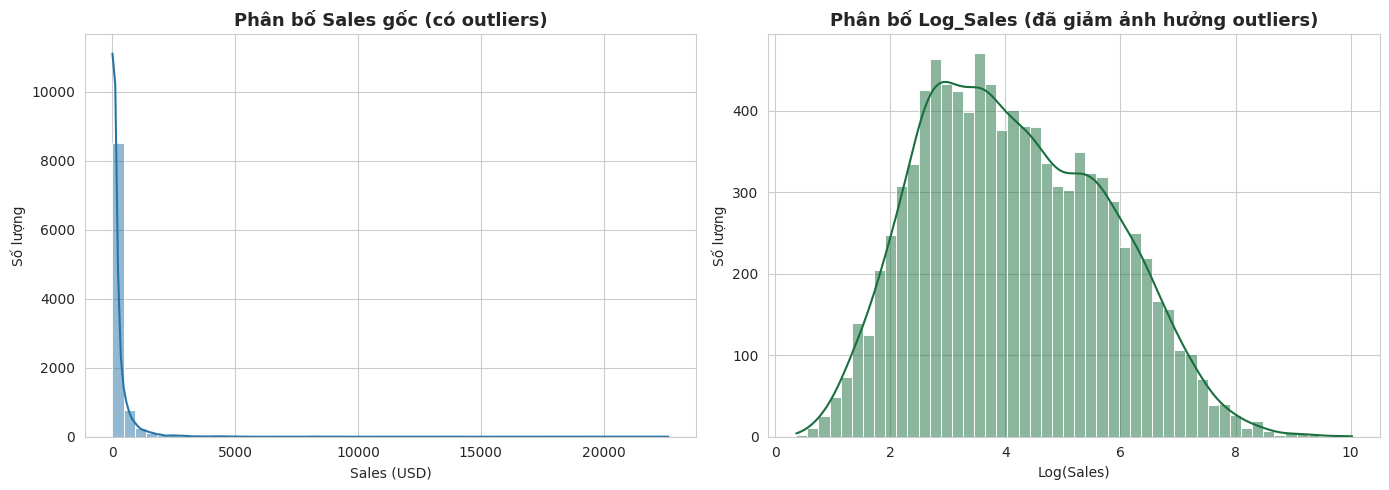

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


=> Đã tự động tải ảnh biểu đồ và file CSV sạch về máy tính của bạn!


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Tự động đọc file train.csv (tương thích cả Google Colab lẫn máy cá nhân)
if os.path.exists("train.csv"):
    duong_dan = "train.csv"
elif os.path.exists("../data/raw/train.csv"):
    duong_dan = "../data/raw/train.csv"
else:
    duong_dan = "../../data/raw/train.csv"

df = pd.read_csv(duong_dan)

# 2. Làm sạch dữ liệu & tạo cột thời gian (giống hệt chuẩn của nhóm bạn)
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True, errors="coerce")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], dayfirst=True, errors="coerce")
df = df.dropna(subset=["Postal Code"]).copy()

df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Quarter"] = df["Order Date"].dt.quarter
df["DayOfWeek"] = df["Order Date"].dt.day_name()

# 3. Phát hiện Outlier bằng IQR và xử lý bằng 2 phương pháp (Log_Sales & IQR Capping)
Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)
IQR = Q3 - Q1
low = Q1 - 1.5 * IQR
high = Q3 + 1.5 * IQR

outliers = df[(df["Sales"] < low) | (df["Sales"] > high)]
print(f"=== THỐNG KÊ OUTLIER TRÊN TẬP DỮ LIỆU ĐÃ LÀM SẠCH ({len(df)} DÒNG) ===")
print(f"- Số lượng Outliers phát hiện theo IQR: {len(outliers)}/{len(df)} dòng ({len(outliers)/len(df)*100:.2f}%)")
print(f"- Ngưỡng IQR hợp lệ: [{low:.2f} USD, {high:.2f} USD]\n")

# Phương pháp 1 (Theo file của bạn cùng nhóm): Tạo cột Log_Sales
df["Log_Sales"] = np.log1p(df["Sales"])

# Phương pháp 2 (Bổ sung thêm): Tạo cột Sales_Capped và đánh dấu Is_Outlier
df["Is_Outlier"] = ((df["Sales"] < low) | (df["Sales"] > high)).astype(int)
df["Sales_Capped"] = np.clip(df["Sales"], low, high)

print("=== SO SÁNH THỐNG KÊ TRƯỚC VÀ SAU XỬ LÝ ===")
print(df[["Sales", "Log_Sales", "Sales_Capped"]].describe().round(2))

# 4. Vẽ biểu đồ chuẩn theo format của nhóm (11_sales_vs_log_sales.png)
sns.set_style("whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["Sales"], bins=50, kde=True, ax=axes[0], color="#2874A6")
axes[0].set_title("Phân bố Sales gốc (có outliers)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Sales (USD)")
axes[0].set_ylabel("Số lượng")

sns.histplot(df["Log_Sales"], bins=50, kde=True, ax=axes[1], color="#196F3D")
axes[1].set_title("Phân bố Log_Sales (đã giảm ảnh hưởng outliers)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Log(Sales)")
axes[1].set_ylabel("Số lượng")

plt.tight_layout()
plt.savefig("11_sales_vs_log_sales.png", dpi=150, bbox_inches="tight")
plt.show()

# 5. Lưu file dữ liệu đã xử lý và TỰ ĐỘNG TẢI VỀ MÁY TÍNH
df.to_csv("train_cleaned_outliers.csv", index=False)

try:
    from google.colab import files
    files.download("11_sales_vs_log_sales.png")
    files.download("train_cleaned_outliers.csv")
    print("\n=> Đã tự động tải ảnh biểu đồ và file CSV sạch về máy tính của bạn!")
except:
    pass